In [3]:
# pip install scikit-learn

In [4]:
# pip install matplotlib

In [5]:
# pip install seaborn

In [6]:
# pip install imbalanced-learn

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import classification_report,ConfusionMatrixDisplay,accuracy_score
import pickle
import warnings
warnings.filterwarnings('ignore')

In [8]:
df=pd.read_csv(r"C:\Users\user\OneDrive\Desktop\diabetes_prediction_dataset.csv")
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [9]:
df['hypertension'].value_counts()

hypertension
0    92515
1     7485
Name: count, dtype: int64

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [11]:
df.shape

(100000, 9)

In [12]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [13]:
df.tail()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0
99999,Female,57.0,0,0,current,22.43,6.6,90,0


In [14]:
df.isna().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [15]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [16]:
df.duplicated().sum()

np.int64(3854)

In [17]:
df=df.drop_duplicates()
df.shape

(96146, 9)

In [18]:
df['smoking_history'].value_counts()

smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64

In [19]:
df['gender'].value_counts()

gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

In [20]:
df=df[df['gender']!='Other']

In [21]:
df['gender'].value_counts()

gender
Female    56161
Male      39967
Name: count, dtype: int64

In [22]:
encoder=LabelEncoder()
encoder1=LabelEncoder()
df['gender']=encoder.fit_transform(df['gender'])
df['smoking_history']=encoder1.fit_transform(df['smoking_history'])

In [23]:
mapp=list(zip(encoder.classes_,encoder.transform(encoder.classes_)))
mapp

[('Female', np.int64(0)), ('Male', np.int64(1))]

In [24]:
mapp1=list(zip(encoder1.classes_,encoder1.transform(encoder1.classes_)))
mapp1

[('No Info', np.int64(0)),
 ('current', np.int64(1)),
 ('ever', np.int64(2)),
 ('former', np.int64(3)),
 ('never', np.int64(4)),
 ('not current', np.int64(5))]

In [25]:
df['diabetes'].value_counts()

diabetes
0    87646
1     8482
Name: count, dtype: int64

In [26]:
df.corr()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
gender,1.000000,-0.028670,0.014196,0.078512,-0.079574,-0.023490,0.019928,0.017831,0.037837
age,-0.028670,1.000000,0.257297,0.238449,0.241234,0.344779,0.106708,0.114323,0.264918
hypertension,0.014196,0.257297,1.000000,0.119972,0.087928,0.148124,0.081443,0.084841,0.195696
heart_disease,0.078512,0.238449,0.119972,1.000000,0.023627,0.061382,0.068142,0.070838,0.170701
smoking_history,-0.079574,0.241234,0.087928,0.023627,1.000000,0.183883,0.035458,0.038329,0.088509
bmi,-0.023490,0.344779,0.148124,0.061382,0.183883,1.000000,0.084443,0.092593,0.214951
HbA1c_level,0.019928,0.106708,0.081443,0.068142,0.035458,0.084443,1.000000,0.171717,0.406446
blood_glucose_level,0.017831,0.114323,0.084841,0.070838,0.038329,0.092593,0.171717,1.000000,0.424366
diabetes,0.037837,0.264918,0.195696,0.170701,0.088509,0.214951,0.406446,0.424366,1.000000


<Axes: >

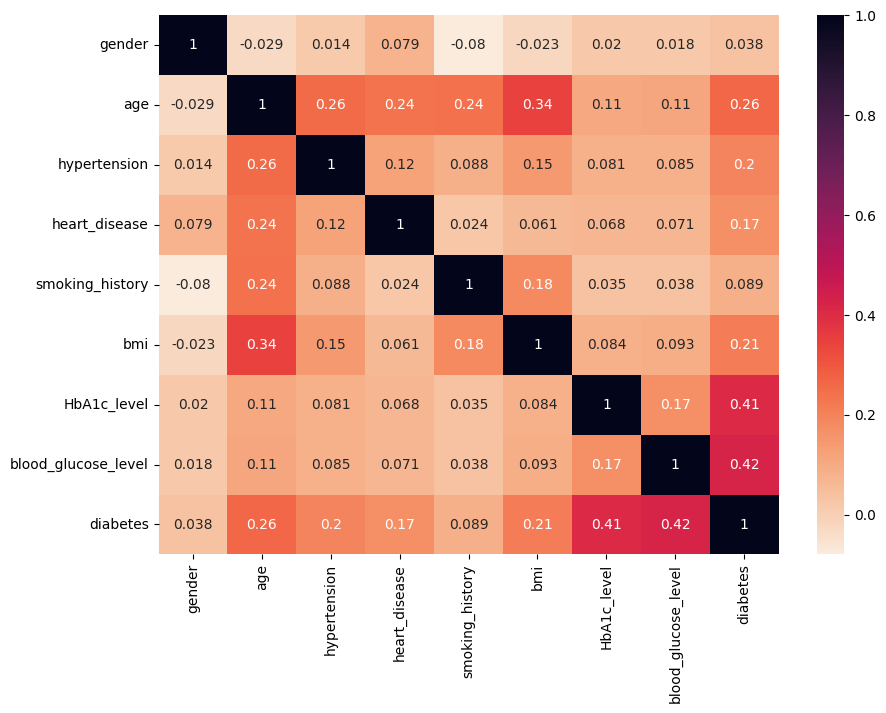

In [27]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(),annot=True,cmap="rocket_r")

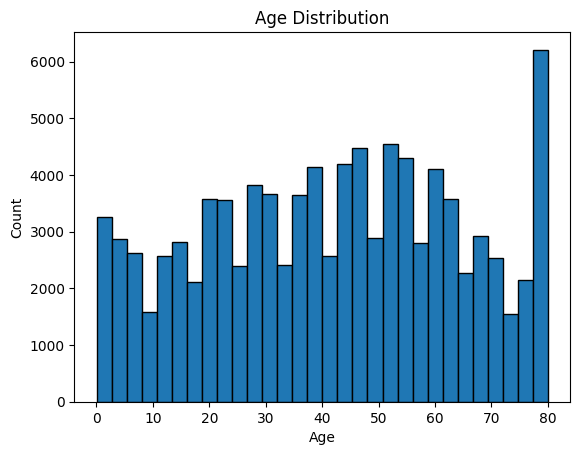

In [28]:
plt.hist(df['age'],bins=30,edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

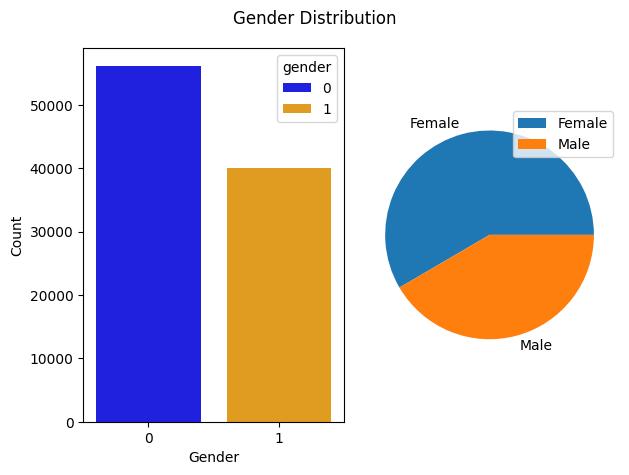

In [29]:
plt.subplot(1,2,1)
sns.countplot(x='gender',data=df,palette=['blue','orange'],hue='gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.suptitle('Gender Distribution')

plt.subplot(1,2,2)
plt.pie(df['gender'].value_counts(),labels=['Female','Male'])
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


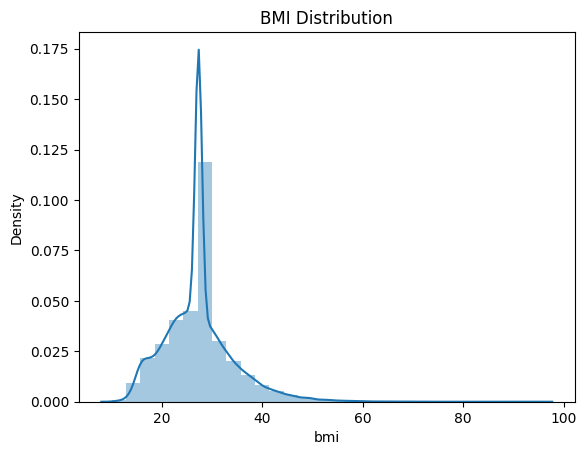

In [30]:
sns.distplot(df['bmi'],bins=30)
plt.title('BMI Distribution')
plt.show()

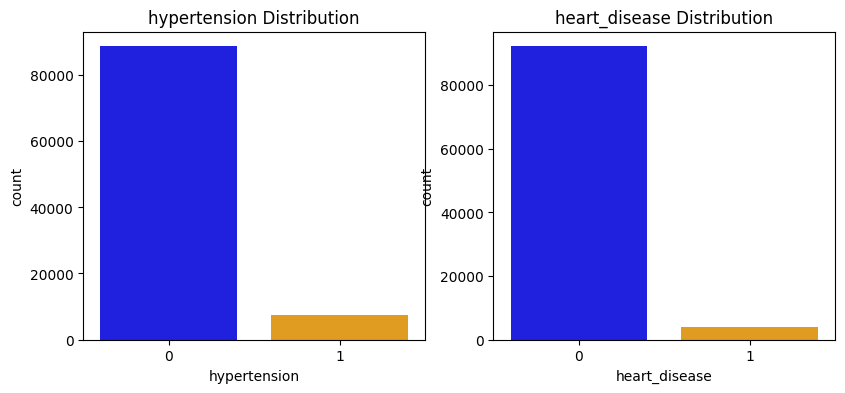

In [31]:
l=['hypertension','heart_disease']
plt.figure(figsize=(15,4))
for j in range(len(l)):
    plt.subplot(1, 3, j+1)
    sns.countplot(x=l[j], data=df, palette=['blue','orange'])
    plt.title(f'{l[j]} Distribution')

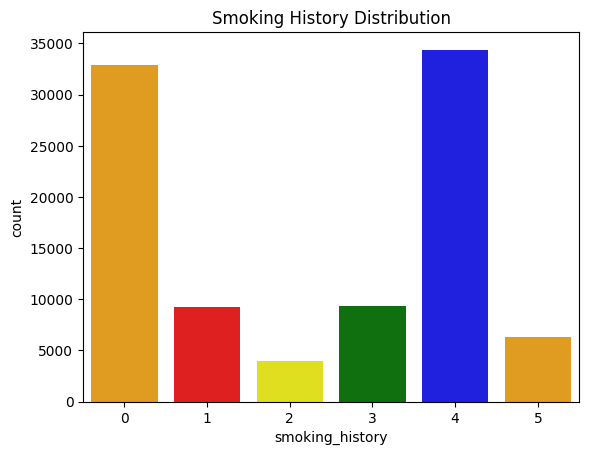

In [32]:
sns.countplot(x='smoking_history', data=df, palette=['orange','red','yellow','green','blue'])
plt.title('Smoking History Distribution')
plt.show()

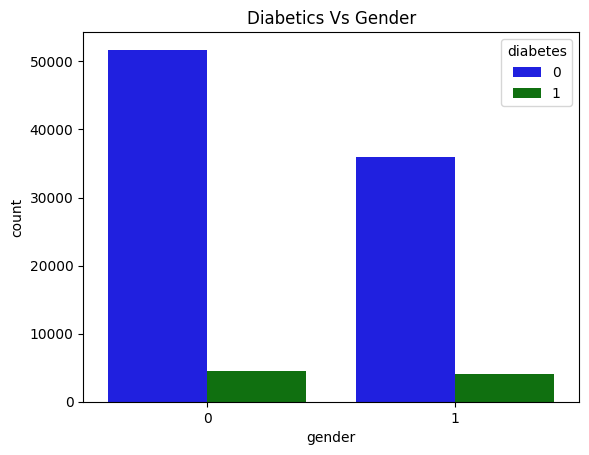

In [33]:
sns.countplot(x='gender', hue='diabetes',data=df,palette=['blue','green'])
plt.title('Diabetics Vs Gender')
plt.show()

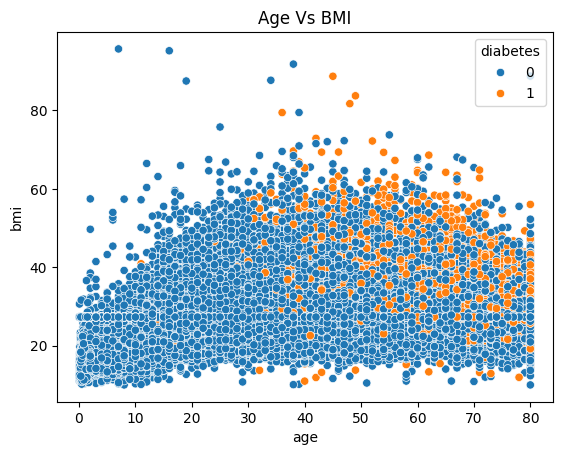

In [34]:
sns.scatterplot(x='age', y='bmi', hue='diabetes',data=df)
plt.title('Age Vs BMI')
plt.show()

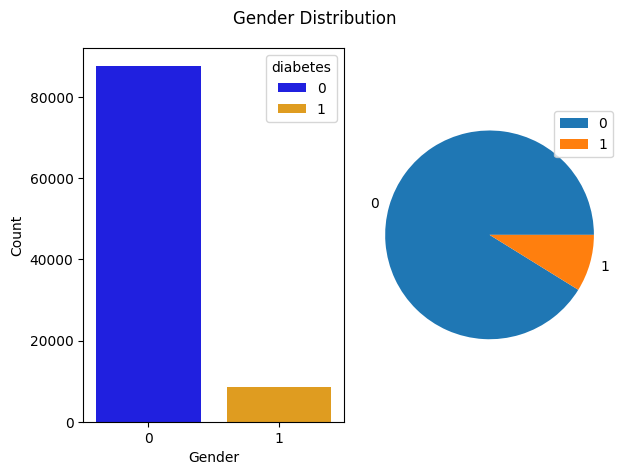

In [35]:
plt.subplot(1,2,1)
sns.countplot(x='diabetes',data=df,palette=['blue','orange'],hue='diabetes')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.suptitle('Gender Distribution')

plt.subplot(1,2,2)
plt.pie(df['diabetes'].value_counts(),labels=[0,1])
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [36]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,0,36.0,0,0,0,24.60,4.8,145,0
99996,0,2.0,0,0,0,17.37,6.5,100,0
99997,1,66.0,0,0,3,27.83,5.7,155,0
99998,0,24.0,0,0,4,35.42,4.0,100,0


In [37]:
x=df.iloc[:,:-1]
x

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,0,80.0,0,1,4,25.19,6.6,140
1,0,54.0,0,0,0,27.32,6.6,80
2,1,28.0,0,0,4,27.32,5.7,158
3,0,36.0,0,0,1,23.45,5.0,155
4,1,76.0,1,1,1,20.14,4.8,155
...,...,...,...,...,...,...,...,...
99994,0,36.0,0,0,0,24.60,4.8,145
99996,0,2.0,0,0,0,17.37,6.5,100
99997,1,66.0,0,0,3,27.83,5.7,155
99998,0,24.0,0,0,4,35.42,4.0,100


In [38]:
y=df.iloc[:,-1]
y=df['diabetes']
y

0        0
1        0
2        0
3        0
4        0
        ..
99994    0
99996    0
99997    0
99998    0
99999    0
Name: diabetes, Length: 96128, dtype: int64

In [39]:
y.value_counts()

diabetes
0    87646
1     8482
Name: count, dtype: int64

In [40]:
over=SMOTE(random_state=1)
x,y=over.fit_resample(x,y)

In [41]:
y.value_counts()


diabetes
0    87646
1    87646
Name: count, dtype: int64

In [42]:
m=MinMaxScaler()
x=m.fit_transform(x)
x

array([[0.        , 1.        , 0.        , ..., 0.17717087, 0.56363636,
        0.27272727],
       [0.        , 0.67467467, 0.        , ..., 0.20203081, 0.56363636,
        0.        ],
       [1.        , 0.34934935, 0.        , ..., 0.20203081, 0.4       ,
        0.35454545],
       ...,
       [0.        , 0.8755913 , 0.        , ..., 0.13201018, 0.41974337,
        0.22727273],
       [0.        , 0.63720636, 0.        , ..., 0.48027738, 0.63661512,
        0.22727273],
       [0.        , 0.75071242, 0.        , ..., 0.51447312, 0.41678298,
        0.35909091]], shape=(175292, 8))

In [43]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=1)


In [44]:
x_train.shape,x_test.shape

((122704, 8), (52588, 8))

                    KNeighborsClassifier()
**************************************
accuracy= 92.76070586445577
              precision    recall  f1-score   support

           0       0.95      0.90      0.93     26406
           1       0.91      0.95      0.93     26182

    accuracy                           0.93     52588
   macro avg       0.93      0.93      0.93     52588
weighted avg       0.93      0.93      0.93     52588



                    RandomForestClassifier(random_state=1)
**************************************
accuracy= 97.1856697345402
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     26406
           1       0.97      0.97      0.97     26182

    accuracy                           0.97     52588
   macro avg       0.97      0.97      0.97     52588
weighted avg       0.97      0.97      0.97     52588



                    DecisionTreeClassifier(random_state=1)
**************************************
accuracy=

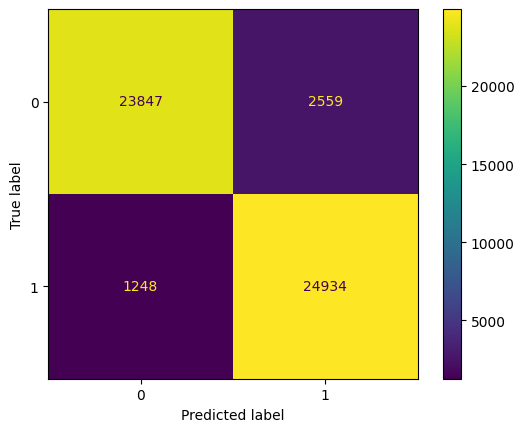

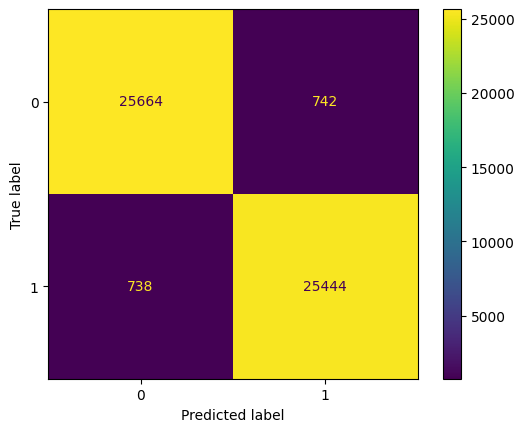

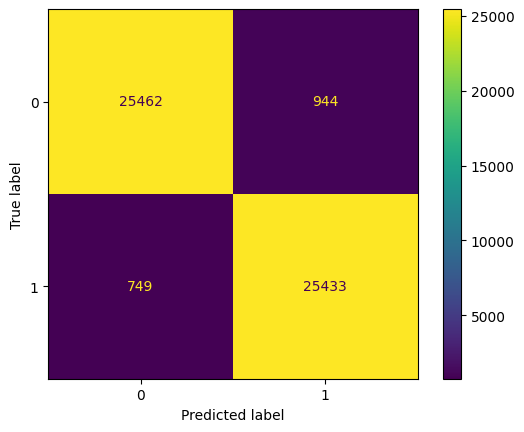

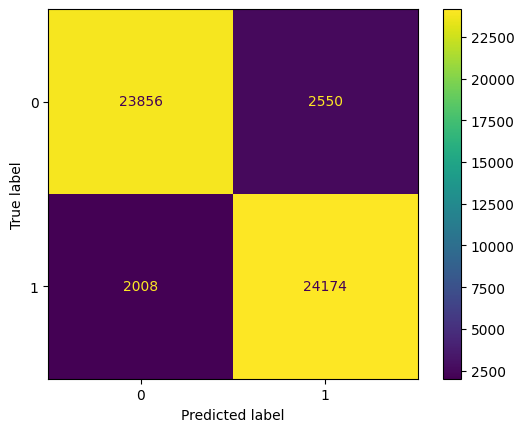

In [45]:
k=KNeighborsClassifier(n_neighbors=5)
r=RandomForestClassifier(n_estimators=100,random_state=1)
d=DecisionTreeClassifier(random_state=1)
a=AdaBoostClassifier(random_state=1)

model=[k,r,d,a]
for i in model:
    print('                   ',i       )
    print('**************************************')
    i.fit(x_train,y_train)
    y_pred=i.predict(x_test)
    print('accuracy=',accuracy_score(y_test,y_pred)*100)
    print(classification_report(y_test,y_pred))
    print(ConfusionMatrixDisplay.from_predictions(y_test,y_pred))
    print()
    print()


In [46]:
from sklearn.model_selection import cross_val_score
import numpy as np
print("Cross Validation Scores for all models on training data:")
for i in model:
    print("              ", i.__class__.__name__)
    print("***************************************************************")
# Using cv=3 and n_jobs =- 1 for faster execution.
    scores = cross_val_score(i, x, y, cv=3, scoring='accuracy', n_jobs =- 1)
    print(f"CV Accuracy Scores: {scores}")
    print(f"Mean Accuracy: {np.mean(scores)*100:.2f}%\n")

Cross Validation Scores for all models on training data:
               KNeighborsClassifier
***************************************************************
CV Accuracy Scores: [0.92069278 0.93094419 0.92926579]
Mean Accuracy: 92.70%

               RandomForestClassifier
***************************************************************
CV Accuracy Scores: [0.95644435 0.9783163  0.97694677]
Mean Accuracy: 97.06%

               DecisionTreeClassifier
***************************************************************
CV Accuracy Scores: [0.95319265 0.97636529 0.97444806]
Mean Accuracy: 96.80%

               AdaBoostClassifier
***************************************************************
CV Accuracy Scores: [0.9090209  0.91615752 0.91622454]
Mean Accuracy: 91.38%



In [47]:
from sklearn.model_selection import RandomizedSearchCV
print("Starting Hyperparameter Tuning for RandomForest ... ")
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf = RandomForestClassifier(random_state=1)
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=1
)

random_search.fit(x_train, y_train)

print("Best Parameters found:", random_search.best_params_)
print("Best CV Score: {:.2f}%".format(random_search.best_score_ * 100))

# Best model
R = random_search.best_estimator_

# Prediction
y_pred_r = R.predict(x_test)

print(y_pred_r)

Starting Hyperparameter Tuning for RandomForest ... 
Best Parameters found: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 30}
Best CV Score: 96.46%
[0 0 1 ... 1 0 1]


In [48]:
R=RandomForestClassifier(n_estimators=100,random_state=1)
R.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [49]:
y_pred_r=R.predict(x_test)
y_pred_r

array([0, 0, 1, ..., 1, 0, 0], shape=(52588,))

accuracy= 97.1856697345402
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     26406
           1       0.97      0.97      0.97     26182

    accuracy                           0.97     52588
   macro avg       0.97      0.97      0.97     52588
weighted avg       0.97      0.97      0.97     52588



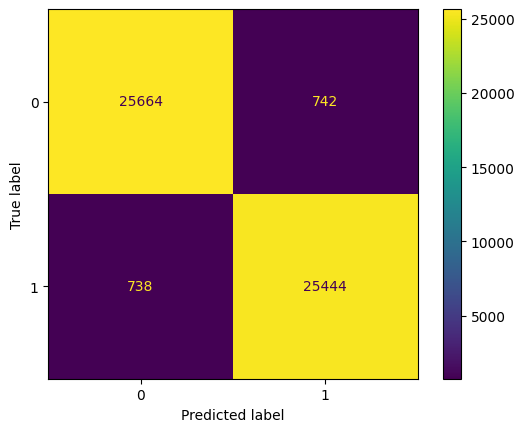

In [50]:
print('accuracy=',accuracy_score(y_test,y_pred_r)*100)
print(classification_report(y_test,y_pred_r))
print(ConfusionMatrixDisplay.from_predictions(y_test,y_pred_r))

In [51]:
# m = StandardScaler()
# m.fit(x_train)  
y_new=R.predict(m.transform([[0,80.0,0,1,4,25.19,6.6,140]]))
if y_new == 0:
    print('No Diabetes')
else:
    print('Diabetes')

No Diabetes


In [52]:
pickle.dump(R,open('diabetes_model.save','wb'))
pickle.dump(m,open('diabetes_scaler.save','wb'))
pickle.dump(encoder,open('diabetics_encoder.save','wb'))
pickle.dump(encoder1,open('diabetics_encoder1.save','wb'))